In [14]:
#Practical 1 – Implementation of 16-Qubit Random Number Generator
%pip install --upgrade qiskit qiskit-aer
from qiskit import QuantumRegister, ClassicalRegister
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# Create 16 quantum qubits
q = QuantumRegister(16, 'q')

# Create 16 classical bits
c = ClassicalRegister(16, 'c')

# Create quantum circuit
circuit = QuantumCircuit(q, c)

# Apply Hadamard gate
circuit.h(q)

# Measure all qubits
circuit.measure(q, c)

# Create simulator
simulator = AerSimulator()

# Execute circuit
compiled_circuit = transpile(circuit, simulator)
job = simulator.run(compiled_circuit, shots=1)

# Get result
result = job.result()
counts = result.get_counts()

# Display output
print("16 Qubit Random Number:")
print(counts)

16 Qubit Random Number:
Result(backend_name='aer_simulator', backend_version='0.18.2', job_id='c5e72429-46e2-420a-80ab-e770858389ec', success=True, results=[ExperimentResult(shots=1, success=True, meas_level=2, data=ExperimentResultData(counts={'0x78f0': 1}), header={'creg_sizes': [['c', 16]], 'global_phase': 0.0, 'memory_slots': 16, 'n_qubits': 16, 'name': 'circuit-62', 'qreg_sizes': [['q', 16]], 'metadata': {}}, status=DONE, seed_simulator=2969381958, metadata={'time_taken': 0.000179075, 'num_bind_params': 1, 'parallel_state_update': 2, 'parallel_shots': 1, 'required_memory_mb': 0, 'input_qubit_map': [[15, 15], [14, 14], [13, 13], [0, 0], [1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10], [11, 11], [12, 12]], 'method': 'stabilizer', 'device': 'CPU', 'num_qubits': 16, 'sample_measure_time': 1.4046e-05, 'active_input_qubits': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 'num_clbits': 16, 'remapped_qubits': False, 'runtime_parameter_bind': False

Original counts:
{'110': 42, '100': 50, '101': 42, '001': 44, '010': 50, '000': 379, '011': 42, '111': 351}
Mitigated counts:
{'000': np.float64(512.5526244640995), '001': np.float64(0.0), '010': np.float64(5.619713413927619), '011': np.float64(0.0), '100': np.float64(5.619713413927619), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(476.2079487080453)}


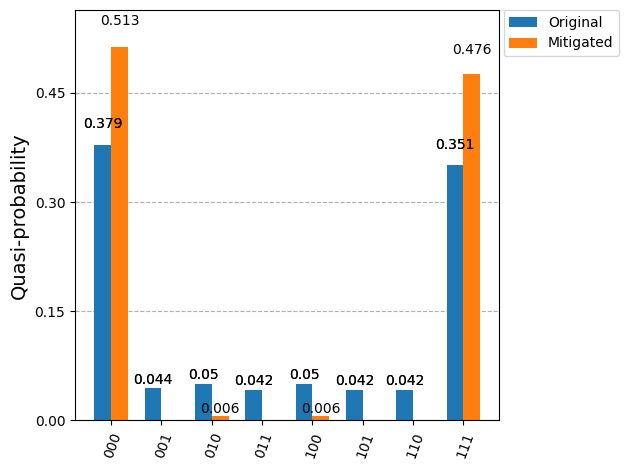

In [21]:
#Practical 2 – Tackle Noise with Error Correction

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError
from qiskit.visualization import plot_histogram

qc = QuantumCircuit(3, 3)

qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.measure([0, 1, 2], [0, 1, 2])

readout_error = ReadoutError([
    [0.9, 0.1],
    [0.1, 0.9]
])

noise_model = NoiseModel()
noise_model.add_all_qubit_readout_error(readout_error)

simulator = AerSimulator(noise_model=noise_model)

compiled_qc = transpile(qc, simulator)
shots = 1000

job = simulator.run(compiled_qc, shots=shots)
result = job.result()
counts = result.get_counts()

calibration = np.array([
    [0.9, 0.1],
    [0.1, 0.9]
])

calibration_matrix = np.kron(
    np.kron(calibration, calibration), calibration
)

observed = np.zeros(8)

for bitstring, count in counts.items():
    observed[int(bitstring, 2)] = count / shots

mitigated = np.linalg.solve(calibration_matrix, observed)
mitigated = np.clip(mitigated, 0, None)
mitigated = mitigated / mitigated.sum()

mitigated_counts = {
    format(i, "03b"): mitigated[i] * shots
    for i in range(8)
}

print("Original counts:")
print(counts)

print("Mitigated counts:")
print(mitigated_counts)

plot_histogram(
    [counts, mitigated_counts],
    legend=["Original", "Mitigated"]
)


     ┌───┐ ░                ┌───┐ ░ ┌─┐    ░            
q_0: ┤ X ├─░─────────────■──┤ H ├─░─┤M├────░───────■────
     └───┘ ░ ┌───┐     ┌─┴─┐└───┘ ░ └╥┘┌─┐ ░       │    
q_1: ──────░─┤ H ├──■──┤ X ├──────░──╫─┤M├─░───■───┼────
           ░ └───┘┌─┴─┐└───┘      ░  ║ └╥┘ ░ ┌─┴─┐ │ ┌─┐
q_2: ──────░──────┤ X ├───────────░──╫──╫──░─┤ X ├─■─┤M├
           ░      └───┘           ░  ║  ║  ░ └───┘   └╥┘
c: 3/════════════════════════════════╩══╩═════════════╩═
                                     0  1             2 
Quantum Teleportation Results:
{'100': 239, '111': 270, '110': 261, '101': 230}


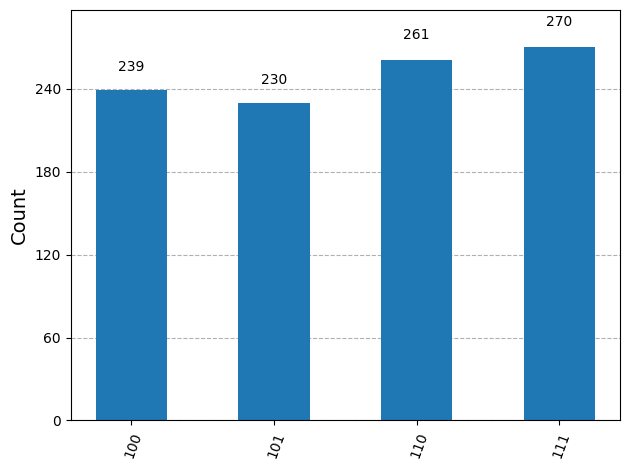

In [17]:
#Practical 4 – Quantum Teleportation Algorithm in Python
%pip install qiskit qiskit-aer matplotlib


from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Step 1: Create a circuit with 3 qubits and 3 classical bits
circuit = QuantumCircuit(3, 3)

# Step 2: Apply X gate on qubit 0
circuit.x(0)
circuit.barrier()

# Step 3: Create entanglement between qubit 1 and 2
circuit.h(1)
circuit.cx(1, 2)

# Step 4: Apply CX and Hadamard gates
circuit.cx(0, 1)
circuit.h(0)
circuit.barrier()

# Step 5: Measure qubit 0 and qubit 1
circuit.measure([0, 1], [0, 1])

# Step 6: Apply controlled X and controlled Z gates
circuit.barrier()
circuit.cx(1, 2)
circuit.cz(0, 2)

# Step 7: Measure qubit 2
circuit.measure(2, 2)

# Step 8: Display quantum circuit
print(circuit.draw())

# Step 9: Create simulator
simulator = AerSimulator()

# Step 10: Execute circuit 1000 times
compiled_circuit = transpile(circuit, simulator)
job = simulator.run(compiled_circuit, shots=1000)

# Step 11: Get results
result = job.result()
counts = result.get_counts()

# Step 12: Display output
print("Quantum Teleportation Results:")
print(counts)

# Step 13: Display histogram
plot_histogram(counts)



/tmp/ipykernel_870/767287740.py:14: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(


     ┌───┐┌──────┐┌─┐            
q_0: ┤ X ├┤0     ├┤M├────────────
     └───┘│      │└╥┘┌─┐         
q_1: ─────┤1     ├─╫─┤M├─────────
     ┌───┐│      │ ║ └╥┘┌─┐      
q_2: ┤ X ├┤2 QFT ├─╫──╫─┤M├──────
     └───┘│      │ ║  ║ └╥┘┌─┐   
q_3: ─────┤3     ├─╫──╫──╫─┤M├───
     ┌───┐│      │ ║  ║  ║ └╥┘┌─┐
q_4: ┤ X ├┤4     ├─╫──╫──╫──╫─┤M├
     └───┘└──────┘ ║  ║  ║  ║ └╥┘
c: 5/══════════════╩══╩══╩══╩══╩═
                   0  1  2  3  4 
QFT Output:
{'11010': 27, '10000': 37, '01001': 28, '10001': 31, '00101': 31, '10011': 31, '01010': 26, '10010': 31, '11100': 38, '10101': 40, '01011': 39, '11101': 32, '11110': 28, '00010': 31, '11000': 44, '01101': 24, '00001': 34, '00110': 33, '01100': 29, '01000': 27, '01111': 21, '10111': 33, '10100': 32, '00100': 33, '11111': 25, '11011': 30, '11001': 25, '00000': 35, '00011': 30, '00111': 20, '10110': 40, '01110': 35}


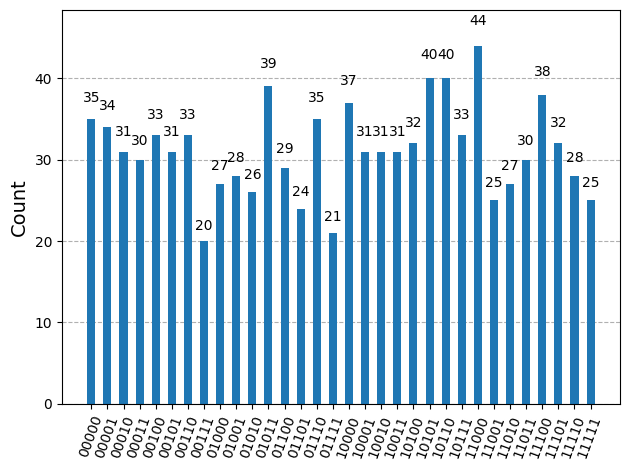

In [20]:
#Practical 5 – Implementing a 5-Qubit Quantum Fourier Transform (QFT)
%pip install qiskit qiskit-aer matplotlib
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QFT
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

circuit = QuantumCircuit(5, 5)

circuit.x(4)
circuit.x(2)
circuit.x(0)

qft = QFT(
    num_qubits=5,
    approximation_degree=0,
    do_swaps=True,
    inverse=False,
    insert_barriers=True
)

circuit.append(qft, range(5))

circuit.measure(range(5), range(5))

print(circuit.draw())

simulator = AerSimulator()
compiled_circuit = transpile(circuit, simulator)

job = simulator.run(compiled_circuit, shots=1000)
result = job.result()
counts = result.get_counts()

print("QFT Output:")
print(counts)

plot_histogram(counts)